# Homework 07: Integer programming models and logic

**ISyE 524 — Fall 2026**  
**Due:** Monday, November 2, 2026, at 11:59 p.m. (Madison time).

Complete all three problems. Model on/off operating ranges, logical
commitments, and minimum set covering. Write your mathematical formulation
before implementing it in Julia/JuMP. Use HiGHS and check solver status and
solution availability before reading values. Decision-variable definitions
are supplied; formulate the objectives and constraints and explain your reasoning.

Submit **one PDF to Gradescope** and mark which pages belong to each problem.
**You will not receive full marks unless you mark the pages.**


## Getting started and written answers

Follow [Assignments and PDF Submission](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/canvas-assignment-workflow.md). In VS Code, use **Tasks: Run Task** to run **ISyE 524: Update course repository**, then **ISyE 524: Start an assignment from its template**, entering `hw07`. Open `student-work/hw07/hw07.ipynb`. An existing working copy will not be overwritten.

For **every written part**, type LaTeX mathematics in Markdown or insert a clear photograph/scan of handwritten work. Include the answer and reasoning together and label the subparts; no duplicate transcription is required. Julia/JuMP implementations belong in code cells.

Use `$x_1 \geq 0$` for inline mathematics and `$$x_1+x_2\leq5$$` for display mathematics. Run the Markdown cell to render it.

For handwritten work, edit a Markdown cell in VS Code, drag in a cropped PNG/JPEG, and choose **Insert Image as Attachment**. Alternatively, put the image beside your working notebook under `student-work/hw07/images/` and insert `![My answer](images/problem1.png)`. Keep external images with the notebook. See [Images and handwritten work](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/assignments.md#images-and-handwritten-work).

Back up `student-work/hw07/` separately; Git does not back up your answers or images. After completing the notebook, export it with the course PDF task, inspect `submissions/hw07.pdf` for readable mathematics, tables, outputs, and images, and submit that PDF to Gradescope.


## Computational setup

Use the course Julia environment. All numerical data are supplied below;
no separate data files are required. Complete the model and reporting cells.
The supplied setup and data cells run without unfinished answers.

AI tools may help debug your own code, explain syntax or error messages,
and critique your work. They should not replace constructing your formulation,
implementation, or written solution. Complete the required collaboration
and LLM-use statement at the end.


In [61]:
using JuMP, HiGHS, Printf
import MathOptInterface as MOI


## 1: Steam power with operating minimums

A power plant has three boilers feeding a common steam header and three
turbines that draw from it. In one planning period, each boiler and turbine
is either off or operates between its stated minimum and maximum. Steam
from any boiler may supply any turbine. Steam may be left unused.
There are no fixed startup costs.

| Boiler $i$ | Minimum steam if on (tons) | Maximum steam (tons) | Steam cost ($/ton) |
| :--- | ---: | ---: | ---: |
| B1 | 400 | 1,000 | 10 |
| B2 | 200 | 900 | 8 |
| B3 | 300 | 800 | 7 |

| Turbine $j$ | Minimum steam if on (tons) | Maximum steam (tons) | Electricity (kWh/ton) | Processing cost ($/ton) |
| :--- | ---: | ---: | ---: | ---: |
| T1 | 300 | 600 | 4 | 2 |
| T2 | 500 | 800 | 5 | 3 |
| T3 | 600 | 900 | 6 | 4 |

Use indices $i\in B=\{1,2,3\}$ for boilers and $j\in T=\{1,2,3\}$
for turbines, with these **supplied decision variables**:

- $x_i\ge0$: continuous tons of steam produced by boiler $i$.
- $t_j\ge0$: continuous tons of steam processed by turbine $j$.
- $y_i\in\{0,1\}$: 1 if boiler $i$ operates, 0 otherwise.
- $z_j\in\{0,1\}$: 1 if turbine $j$ operates, 0 otherwise.

### 1(a): Formulate and solve

The plant must produce **at least 8,000 kWh**. Formulate a mixed-integer
linear program minimizing total boiler and turbine costs. Include constraints
that connect each device's operating status to its steam quantity, account
for available steam, and meet the electricity requirement. Explain why the
operating-range constraints allow a device to be off.

Implement and solve your model. Report the operating devices, steam produced
by each boiler, steam processed by each turbine, total electricity, and total
cost, with units. Use `x[i]`, `t[j]`, `y[i]`, and `z[j]` for the variables.


**Your formulation and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


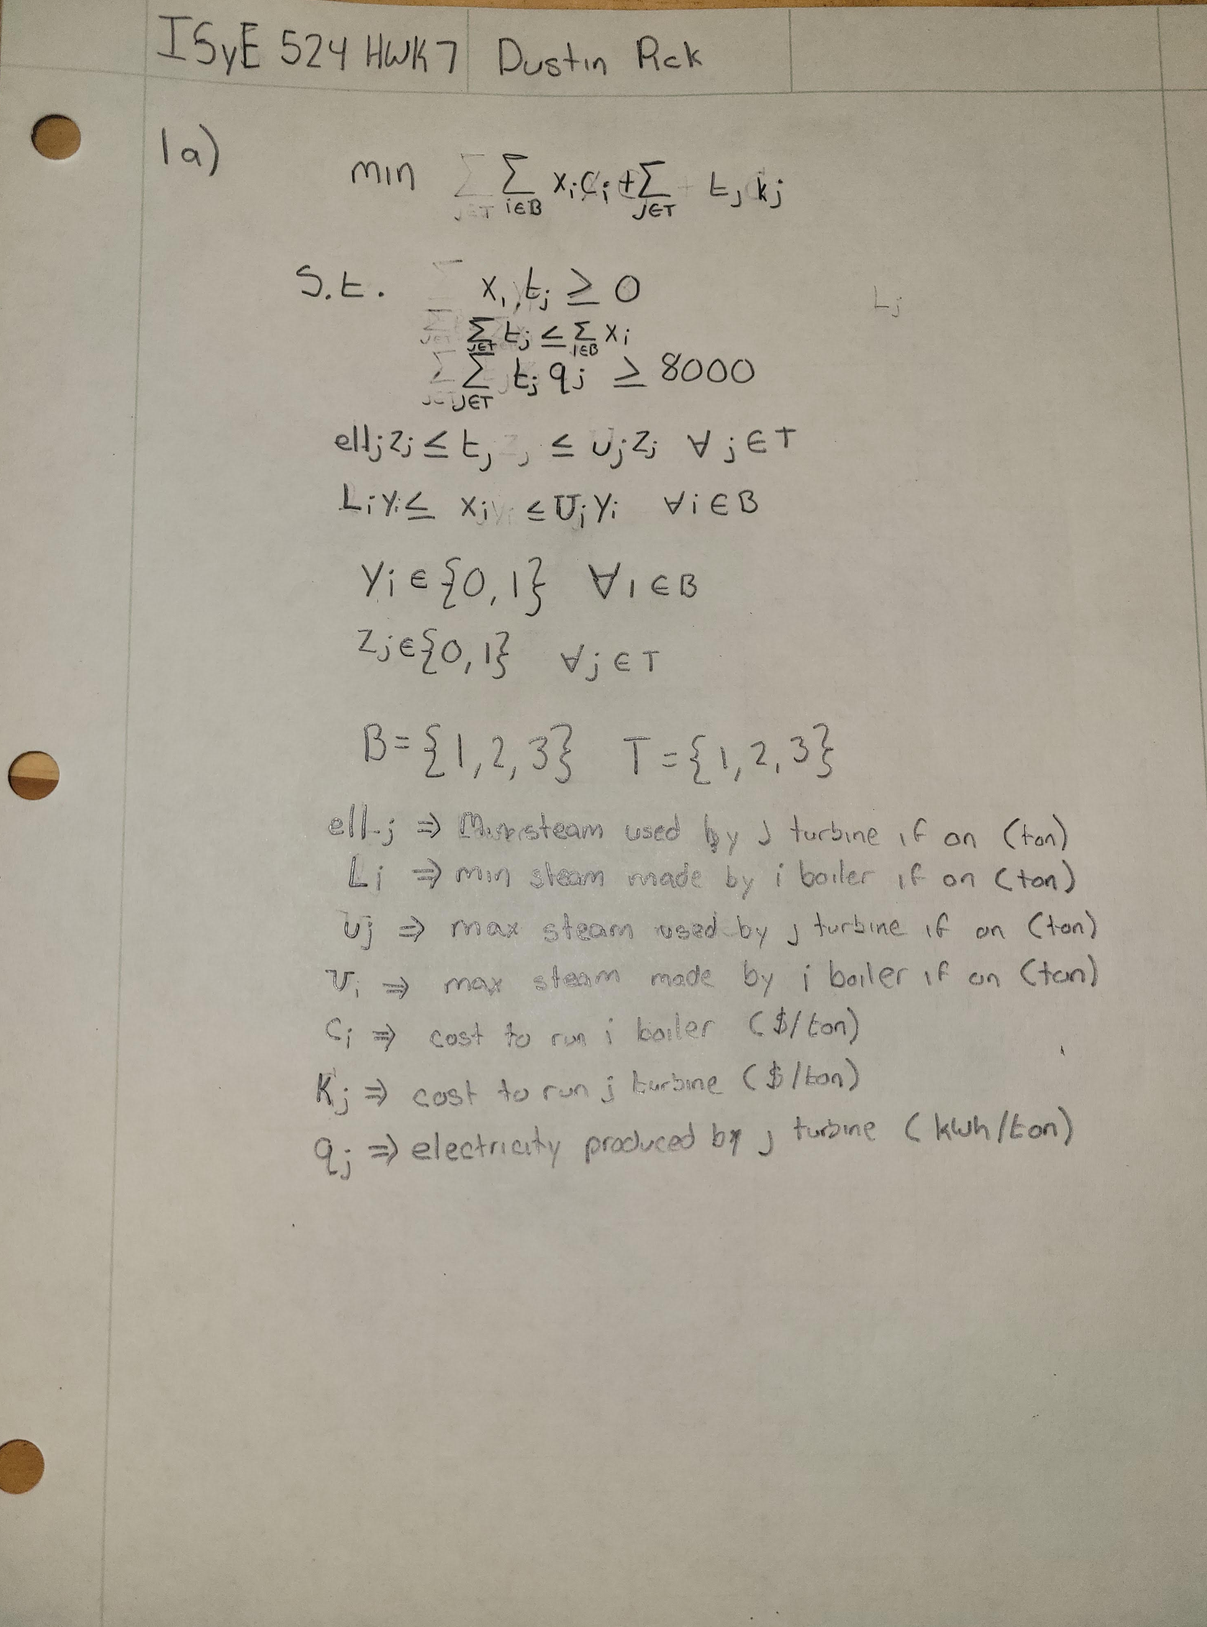

In [62]:
B = 1:3
T = 1:3
L = Dict(zip(B, [400.0, 200.0, 300.0]))
U = Dict(zip(B, [1000.0, 900.0, 800.0]))
c = Dict(zip(B, [10.0, 8.0, 7.0]))
ell = Dict(zip(T, [300.0, 500.0, 600.0]))
u = Dict(zip(T, [600.0, 800.0, 900.0]))
q = Dict(zip(T, [4.0, 5.0, 6.0]))
k = Dict(zip(T, [2.0, 3.0, 4.0]));


In [ ]:
# Build and solve the model for 8,000 kWh.
# You may write a function to reuse the model in 1(b) and 1(c).
# Report device quantities, total electricity, and cost.

m=Model(HiGHS.Optimizer)

@variable(m,z[T], Bin)
@variable(m,y[B], Bin)
@variable(m,x[B]>=0)
@variable(m,t[T]>=0)

@constraint(m, sum(t[j]*q[j] for j in T)>=8000)
@constraint(m,lower_capacity_boiler[i in B], L[i]*y[i]<=x[i])
@constraint(m,upper_capacity_boiler[i in B], x[i]<=U[i]*y[i])
@constraint(m,lower_capacity_turbine[j in T], ell[j]*z[j]<=t[j])
@constraint(m,upper_capacity_turbine[j in T], t[j]<=u[j]*z[j])
@constraint(m, sum(x[i] for i in B)>=sum(t[j] for j in T))

@objective(m, Min, sum(x[i]*c[i] for i in B)+sum(t[j]*k[j] for j in T))

optimize!(m)
if !is_solved_and_feasible(m; allow_local = false)
    error("No optimal primal solution: $(termination_status(m)), $(primal_status(m))")
end

println(termination_status(m))

steam_produced=zeros(3)
steam_processed=zeros(3)
electricity_produced=zeros(3)

for i in T
    steam_produced[i]=value(x[i])
    steam_processed[i]=value(t[i])
    electricity_produced[i]=steam_processed[i]*q[i]
end

println("Steam produced by boiler 1: ", steam_produced[1], " tons")
println("Steam produced by boiler 2: ", steam_produced[2], " tons")
println("Steam produced by boiler 3: ", steam_produced[3], " tons")
println("")
println("Steam processed by turbine 1: ", steam_processed[1], " tons")
println("Steam processed by turbine 2: ", steam_processed[2], " tons")
println("Steam processed by turbine 3: ", steam_processed[3], " tons")
println("")
println("Electricity processed by turbine 1: ", electricity_produced[1], " kWh")
println("Electricity processed by turbine 2: ", electricity_produced[2], " kWh")
println("Electricity processed by turbine 3: ", electricity_produced[3], " kWh")
println("")
println("Total electricity produced: ",
 sum(electricity_produced[i] for i in T), " kWh")
println("Minimum cost: ", objective_value(m), " dollars" )

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 14 rows; 12 cols; 33 nonzeros; 6 integer variables (6 binary)
Coefficient ranges:
  Matrix  [1e+00, 1e+03]
  Cost    [2e+00, 1e+01]
  Bound   [1e+00, 1e+00]
  RHS     [8e+03, 8e+03]
Presolving model
14 rows, 12 cols, 33 nonzeros 0s
10 rows, 10 cols, 25 nonzeros 0s
Presolve reductions: rows 10(-4); columns 10(-2); nonzeros 25(-8) 

Solving MIP model with:
   10 rows
   10 cols (4 binary, 0 integer, 0 implied int., 6 continuous, 0 domain fixed)
   25 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate node; U => Unbounded; X => User solu

**Your reported results:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

The minimum cost for this MIP is 15,720 dollars. To acheive this boiler 1 and turbine 1 are left off and boiler 2 is used to produce 620 tons of steam, boiler 3 is used to produce 800 tons of steam. Turbine 2 processes 520 tons of steam and turbine 3 processes 900 tons of steam to produce 2600 and 5400 kWh of energy respecively.  There is a total of 8000kWh of electricity produced.  

In this MIP the constraints on upper and lower bounds allow the boilers and turbines to be off becasue when $z_j$ or $y_i$ is zero it forces both the upper and lower bound to be 0, which results in $t_j$ or $x_i$ to be sequeezed to 0 representing its off state.


### 1(b): Lower electricity demand

Demand falls to **2,000 kWh**. Keep all operating minimums and maximums.
Solve the model again. Report only the operating devices and their steam
quantities, electricity, and total cost. Explain the change in turbine choice
from 1(a).


In [ ]:
# Solve the same operating-range model for 2,000 kWh and report
# the plan.
mb=Model(HiGHS.Optimizer)

@variable(mb,z[T], Bin)
@variable(mb,y[B], Bin)
@variable(mb,x[B]>=0)
@variable(mb,t[T]>=0)

@constraint(mb, sum(t[j]*q[j] for j in T)>=2000)
@constraint(mb,lower_capacity_boiler[i in B], L[i]*y[i]<=x[i])
@constraint(mb,upper_capacity_boiler[i in B], x[i]<=U[i]*y[i])
@constraint(mb,lower_capacity_turbine[j in T], ell[j]*z[j]<=t[j])
@constraint(mb,upper_capacity_turbine[j in T], t[j]<=u[j]*z[j])
@constraint(mb, sum(x[i] for i in B)>=sum(t[j] for j in T))

@objective(mb, Min, sum(x[i]*c[i] for i in B)+sum(t[j]*k[j] for j in T))

optimize!(mb)
if !is_solved_and_feasible(mb; allow_local = false)
    error("No optimal primal solution: $(termination_status(mb)), $(primal_status(mb))")
end

println(termination_status(mb))

steam_produced=zeros(3)
steam_processed=zeros(3)
electricity_produced=zeros(3)

for i in T
    steam_produced[i]=value(x[i])
    steam_processed[i]=value(t[i])
    electricity_produced[i]=steam_processed[i]*q[i]
end

println("Steam produced by boiler 1: ", steam_produced[1], " tons")
println("Steam produced by boiler 2: ", steam_produced[2], " tons")
println("Steam produced by boiler 3: ", steam_produced[3], " tons")
println("")
println("Steam processed by turbine 1: ", steam_processed[1], " tons")
println("Steam processed by turbine 2: ", steam_processed[2], " tons")
println("Steam processed by turbine 3: ", steam_processed[3], " tons")
println("")
println("Electricity processed by turbine 1: ", electricity_produced[1], " kWh")
println("Electricity processed by turbine 2: ", electricity_produced[2], " kWh")
println("Electricity processed by turbine 3: ", electricity_produced[3], " kWh")
println("")
println("Total electricity produced: ",
 sum(electricity_produced[i] for i in T), " kWh")
println("Minimum cost: ", objective_value(mb), " dollars" )

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 14 rows; 12 cols; 33 nonzeros; 6 integer variables (6 binary)
Coefficient ranges:
  Matrix  [1e+00, 1e+03]
  Cost    [2e+00, 1e+01]
  Bound   [1e+00, 1e+00]
  RHS     [2e+03, 2e+03]
Presolving model
14 rows, 12 cols, 33 nonzeros 0s
14 rows, 12 cols, 33 nonzeros 0s
Presolve reductions: rows 14(-0); columns 12(-0); nonzeros 33(-0) - Not reduced

Solving MIP model with:
   14 rows
   12 cols (6 binary, 0 integer, 0 implied int., 6 continuous, 0 domain fixed)
   33 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate node; U => Unbounded; X

**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

In this problem it is best to keep boiler 1 and 2 off as well as turbine 2 and 3 off.  This will result in producing 500 tons of steam with boiler 3 and processing 500 tons of steam with turbine 1, resulting in a total energy production of 2000 kWh and a cost of 4500 dollars.  In this senario it is better to use turbine 1 beacuse all of the capacity can be used and it has the lowest opperating cost whereas in the 8000 kWh demand it was better to use the bigger turbines which require more steam to run but are much more efficent in output vs cost.

### 1(c): What if operating minimums are ignored?

Keep demand at **2,000 kWh**. Suppose devices may now operate at any
nonnegative level up to their maximum when enabled. Remove only the
operating-minimum constraints, keeping all other constraints and costs.
Solve again. Report the positive steam quantities, electricity, and cost.
Compare the cost with 1(b), and identify the operating requirement violated
by this plan under the original rules.


In [ ]:
# Solve the 2,000-kWh case with only the operating minimums
# removed.

# Solve the same operating-range model for 2,000 kWh and report
# the plan.
community=Model(HiGHS.Optimizer)

@variable(community,z[T], Bin)
@variable(community,y[B], Bin)
@variable(community,x[B]>=0)
@variable(community,t[T]>=0)

@constraint(community, sum(t[j]*q[j] for j in T)>=2000)
@constraint(community,lower_capacity_boiler[i in B], 0<=x[i])
@constraint(community,upper_capacity_boiler[i in B], x[i]<=U[i]*y[i])
@constraint(community,lower_capacity_turbine[j in T], 0<=t[j])
@constraint(community,upper_capacity_turbine[j in T], t[j]<=u[j]*z[j])
@constraint(community, sum(x[i] for i in B)>=sum(t[j] for j in T))

@objective(community, Min, sum(x[i]*c[i] for i in B)+sum(t[j]*k[j] for j in T))

optimize!(community)
if !is_solved_and_feasible(community; allow_local = false)
    error("No optimal primal solution: $(termination_status(community)), $(primal_status(community))")
end

println(termination_status(community))

steam_produced=zeros(3)
steam_processed=zeros(3)
electricity_produced=zeros(3)

for i in T
    steam_produced[i]=value(x[i])
    steam_processed[i]=value(t[i])
    electricity_produced[i]=steam_processed[i]*q[i]
end

println("Steam produced by boiler 1: ", steam_produced[1], " tons")
println("Steam produced by boiler 2: ", steam_produced[2], " tons")
println("Steam produced by boiler 3: ", steam_produced[3], " tons")
println("")
println("Steam processed by turbine 1: ", steam_processed[1], " tons")
println("Steam processed by turbine 2: ", steam_processed[2], " tons")
println("Steam processed by turbine 3: ", steam_processed[3], " tons")
println("")
println("Electricity processed by turbine 1: ", electricity_produced[1], " kWh")
println("Electricity processed by turbine 2: ", electricity_produced[2], " kWh")
println("Electricity processed by turbine 3: ", electricity_produced[3], " kWh")
println("")
println("Total electricity produced: ",
 sum(electricity_produced[i] for i in T), " kWh")
println("Minimum cost: ", objective_value(community), " dollars" )


Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 14 rows; 12 cols; 27 nonzeros; 6 integer variables (6 binary)
Coefficient ranges:
  Matrix  [1e+00, 1e+03]
  Cost    [2e+00, 1e+01]
  Bound   [1e+00, 1e+00]
  RHS     [2e+03, 2e+03]
Presolving model
8 rows, 6 cols, 15 nonzeros 0s
2 rows, 6 cols, 9 nonzeros 0s
Presolve reductions: rows 2(-12); columns 6(-6); nonzeros 9(-18) 

Solving MIP model with:
   2 rows
   6 cols (0 binary, 0 integer, 0 implied int., 6 continuous, 0 domain fixed)
   9 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate node; U => Unbounded; X => User solution; Y =

**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

If minimums opperating constrints are removed then it is best to leave boiler 1 and 2 off as well as turbine 1 and 2.  Then 334 tons of steam will be produced by boiler 3 and processed by turbine 3 to resut in 2000 kWh for a cost of 3667 dollars.  This produces a lower cost than having minimum opperating requrements becasue it can use the most efficent turbine in terms of ouput per cost but it violates the minimum posed in the original rules becasue it only used 333 tons of capacity of turbine 3 when its minimum is 600 tons. 

## 2: Community projects with logical commitments

A community organization has **$24,000** for projects. Each project must
be undertaken completely or omitted. Costs below are in **thousands of
dollars**. Impact points are a planning score that adds across projects.
Field-team hours are the total hours required by each selected project.

| Project $p$ | Description | Cost $c_p$ | Impact $b_p$ | Hours $h_p$ |
| :--- | :--- | ---: | ---: | ---: |
| A | Community garden | 7 | 13 | 6 |
| B | Food-truck pop-up | 6 | 12 | 5 |
| C | Volunteer training | 5 | 9 | 4 |
| D | Tool library | 4 | 8 | 4 |
| E | Storage upgrade | 3 | 5 | 2 |
| F | Compost hub | 4 | 7 | 3 |
| G | Soil workshop | 2 | 4 | 1 |
| H | Nutrition class | 5 | 10 | 5 |

The organization has five operating commitments:

1. The garden requires volunteer training or the tool library, or both.
2. The food-truck pop-up and tool library cannot both be undertaken because
   they need the same trailer.
3. If both volunteer training and the tool library are undertaken, the
   storage upgrade must also be undertaken. The upgrade may be selected
   independently.
4. The compost hub and soil workshop must be undertaken together or both
   omitted.
5. Exactly one of the food-truck pop-up and nutrition class must be selected.

Selecting both the garden and nutrition class earns **four additional
impact points** for their combined program. This bonus is awarded once,
and only when both are selected. There is no other limit on total hours
in parts (a)–(b).

Use these **supplied decision variables**:

- $x_p\in\{0,1\}$ for $p\in P=\{A,B,C,D,E,F,G,H\}$: 1 if project $p$
  is selected, 0 otherwise.
- $w\in\{0,1\}$: 1 if and only if both A and H are selected.

### 2(a): Formulate the logical selection model

Formulate a binary linear program maximizing total impact, including the
joint-program bonus, subject to the budget and all five commitments.
Ensure the constraints give $w$ its stated meaning in every feasible
solution. Label the constraints corresponding to commitments 1–5.

Explain why commitment 1 permits both supporting projects and why commitment
3 permits the storage upgrade even when the training and tool library are
not both selected. Do not use products of decision variables.


**Your formulation and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

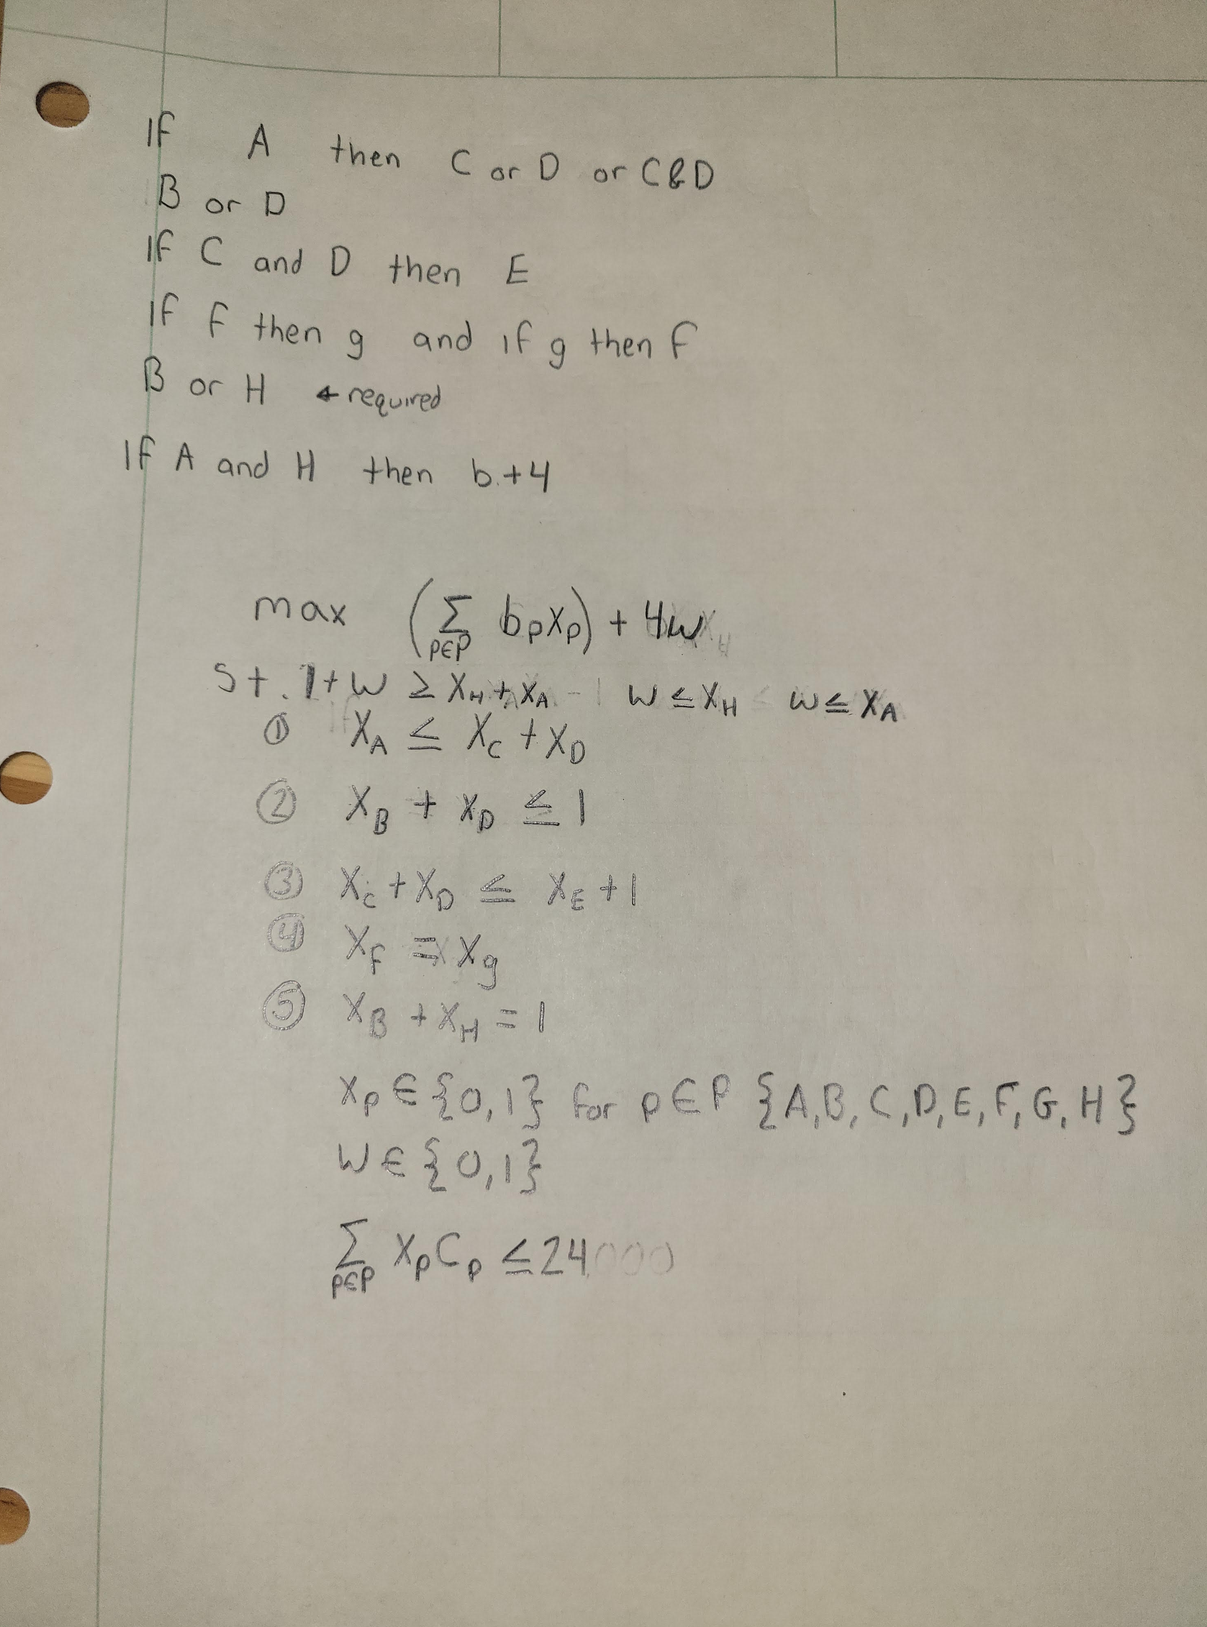


The constraint $ X_A \leq X_C + X_D $ ensures if a is chosen then C, D, or C and D must be chosen becasue if $X_A =1$ then $X_C =1$ and $X_D = 1$ results in $1 \leq 2$ which makes the stament true. $X_C =0$ and $X_D = 1$ results in $1 \leq 1$ which makes the stament true. $X_C =1$ and $X_D = 0$ results in $1 \leq 1$ which makes the stament true. But $X_C =0$ and $X_D = 0$ results in $1 \leq 0$ which makes the stament false. 

The constraint $X_C + X_D \leq X_E +1$ allows E to be selected when C and D are not both selected becasue it results in $X_C =0$ and $X_D = 0$ $X_E =1$ results in the constraint holding becasue $0 \leq 2$. It also allows one of D or C to be selected as well as E becasue that will result in $1 \leq 2$ the only thing it doesnt allow is E to be 0 and D and C are 1 which would result in $2 \leq 1$ which would make the constraint false.

In [66]:
P = [:A, :B, :C, :D, :E, :F, :G, :H]
c_project = Dict(zip(P, [7, 6, 5, 4, 3, 4, 2, 5]))
b_project = Dict(zip(P, [13, 12, 9, 8, 5, 7, 4, 10]))
h_project = Dict(zip(P, [6, 5, 4, 4, 2, 3, 1, 5]))
budget = 24;  # thousands of dollars



### 2(b): Solve and interpret

Implement and solve the model from 2(a). Use `x[p]` and `w` for the
variables. Report selected projects, project spending in dollars, total
field-team hours, and total impact including any bonus. State which
projects earn the bonus, if it is awarded.


In [67]:
# Build and solve the project-selection model.
# Report selected projects, spending, hours, and impact.

community=Model(HiGHS.Optimizer)

@variable(community,x[P], Bin)
@variable(community,w, Bin)


@constraint(community, sum(x[p]*c_project[p] for p in P)<= budget)
@constraint(community,1+w>=x[:H]+x[:A])
@constraint(community, w <= x[:H])
@constraint(community, w <= x[:A])
@constraint(community,x[:A] <= x[:C]+x[:D])
@constraint(community, x[:D]+x[:B]<=1)
@constraint(community, x[:C]+x[:D]<= x[:E]+1)
@constraint(community, x[:F]==x[:G])
@constraint(community, x[:B]+x[:H]==1)

@objective(community, Max, sum(b_project[p]*x[p] for p in P)+4*w)

optimize!(community)
if !is_solved_and_feasible(community; allow_local = false)
    error("No optimal primal solution: $(termination_status(community)), $(primal_status(community))")
end

println(termination_status(community))

println("Bonus value Status: ", value.(w))
println("Project A status : ", value.(x[:A]))
println("Project B status : ", value.(x[:B]))
println("Project C status : ", value.(x[:C]))
println("Project D status : ", value.(x[:D]))
println("Project E status : ", value.(x[:E]))
println("Project F status : ", value.(x[:F]))
println("Project G status : ", value.(x[:G]))
println("Project H status : ", value.(x[:H]))
println("")
println("Total Cost: ",sum(value.(x[p]*c_project[p] for p in P)), " dollars")
println("")
println("Feild Team hours: ",sum(value.(x[p]*h_project[p] for p in P)), " hours")
println("")
println("Maximum  impact: ", objective_value(community) )

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 9 rows; 9 cols; 27 nonzeros; 9 integer variables (9 binary)
Coefficient ranges:
  Matrix  [1e+00, 7e+00]
  Cost    [4e+00, 1e+01]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 2e+01]
Presolving model
7 rows, 7 cols, 21 nonzeros 0s
7 rows, 7 cols, 21 nonzeros 0s
Presolve reductions: rows 7(-2); columns 7(-2); nonzeros 21(-6) 
Objective function is integral with scale 1

Solving MIP model with:
   7 rows
   7 cols (7 binary, 0 integer, 0 implied int., 0 continuous, 0 domain fixed)
   21 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate no

**Your results and interpretation:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

The maximum impact possible from these programs is 49. This is done by selecting project A,C,D,E,and H. Becasue A and H are selected together the bonus impact is earned. The projects cost 24000 dollars in total and ther is 21 feild team hours used.

### 2(c): A workload-triggered supervisor fee

Now a supervisor must be hired if total field-team hours are **17 or more**.
Below 17 hours, no supervisor is hired. The supervisor costs **$3,000**,
which counts against the **same $24,000 budget**; it adds no impact points.
Keep all five operating commitments and the joint-program bonus.

Use the additional **supplied binary variable** $v$, equal to 1 if and
only if total field-team hours are at least 17. Write the added or changed
linear constraints and justify finite constants using the data. Explain
why the integer hour total permits an exact distinction between fewer
than 17 hours and at least 17 hours.

Implement and solve the revised model, using `v` for the new variable.
Report selected projects, project spending, supervisor cost, combined
spending, hours, and impact. Explain the change from 2(b).


**Your formulation and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

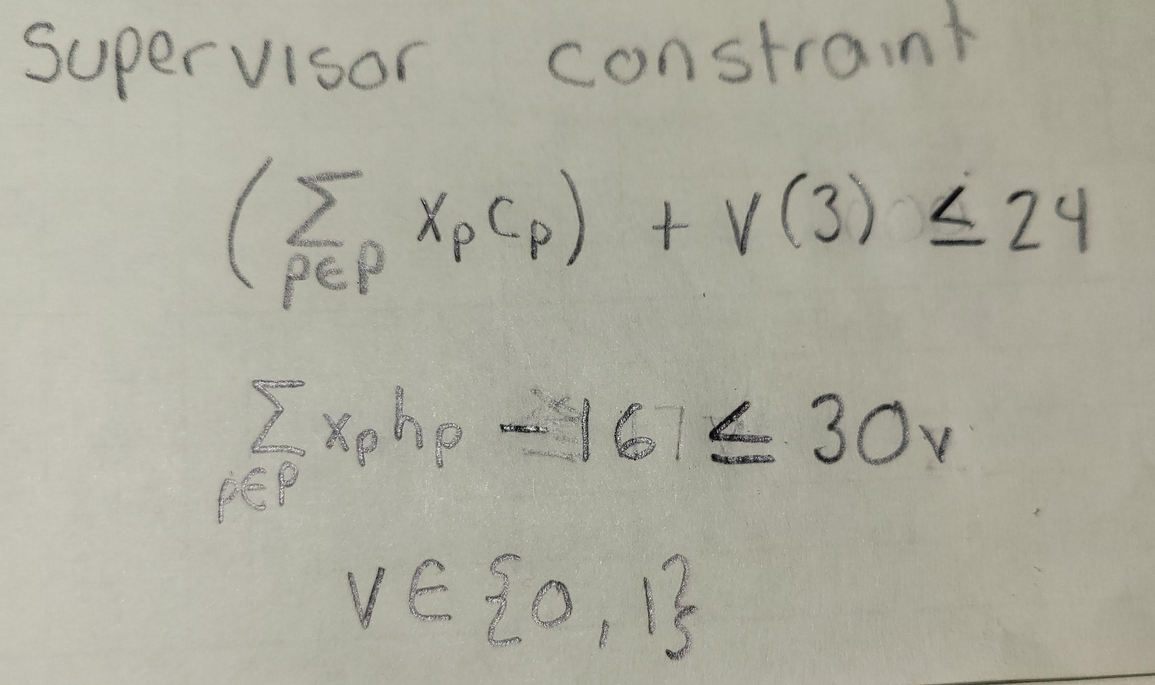


A new term is added to the cost constraint which charges the budged 3000 dollars if the supervisor is needed because when the supervisor is needed v=1 and the cost is active but when the supervisor isnt needed the v=0 and the cost is not added.

The total hours -16 $ \leq 30*z$ constraint makes sure that the v is 1 if hours is 17 or greater. This is becasue any value 16 or lower will result in a value less than 0 so v can remain 0. Any value 17 or greater will be positive and require v to be 1.  30 was chosen as the big M because it is the total possible time if all projects were to be selected, thus it is a safe upper limit. Along with this the fact that all Xp values and hp values are integers means that fewer than 17 results in less than or equal to 16 and at least 17 is the same as greater than or equal to 17.

In [ ]:
# Add the exact workload indicator and include the supervisor in
# the budget.
# Solve and report the revised selection, costs, hours, and
# impact.

communityc=Model(HiGHS.Optimizer)

@variable(communityc,x[P], Bin)
@variable(communityc,w, Bin)
@variable(communityc,v, Bin)

@constraint(communityc, sum(x[p]*c_project[p] for p in P)+v*3<= budget)
@constraint(communityc,1+w>=x[:H]+x[:A])
@constraint(communityc, w <= x[:H])
@constraint(communityc, w <= x[:A])
@constraint(communityc,x[:A] <= x[:C]+x[:D])
@constraint(communityc, x[:D]+x[:B]<=1)
@constraint(communityc, x[:C]+x[:D]<= x[:E]+1)
@constraint(communityc, x[:F]==x[:G])
@constraint(communityc, x[:B]+x[:H]==1)
@constraint(communityc, sum(h_project[p]*x[p] for p in P)-16 <= 30*v)

@objective(communityc, Max, sum(b_project[p]*x[p] for p in P)+4*w)

optimize!(communityc)
if !is_solved_and_feasible(communityc; allow_local = false)
    error("No optimal primal solution: $(termination_status(communityc)), $(primal_status(communityc))")
end

println(termination_status(communityc))

println("Bonus value Status: ", value.(w))
println("Supervisor Status: ", value.(v))
println("Supervisor Cost :", value.(v)*3000, " dollars")
println("")
println("Project A status : ", value.(x[:A]))
println("Project B status : ", value.(x[:B]))
println("Project C status : ", value.(x[:C]))
println("Project D status : ", value.(x[:D]))
println("Project E status : ", value.(x[:E]))
println("Project F status : ", value.(x[:F]))
println("Project G status : ", value.(x[:G]))
println("Project H status : ", value.(x[:H]))
println("")
println("Total Cost: ",sum(value(x[p])*c_project[p] for p in P)+value(v)*3,
 " dollars")
println("")
println("Feild Team hours: ",sum(value(x[p])*h_project[p] for p in P), " hours")
println("")
println("Maximum  impact: ", objective_value(communityc) )

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 10 rows; 10 cols; 37 nonzeros; 10 integer variables (10 binary)
Coefficient ranges:
  Matrix  [1e+00, 3e+01]
  Cost    [4e+00, 1e+01]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 2e+01]
Presolving model
8 rows, 8 cols, 28 nonzeros 0s
8 rows, 8 cols, 28 nonzeros 0s
Presolve reductions: rows 8(-2); columns 8(-2); nonzeros 28(-9) 
Objective function is integral with scale 1

Solving MIP model with:
   8 rows
   8 cols (8 binary, 0 integer, 0 implied int., 0 continuous, 0 domain fixed)
   28 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluat

**Your results and explanation:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

With the added constraints from the supervisor the projects selected are A,C,E,and H. Becasue A and H are selected the bonus impact is earned. The maximum impact possible from this new set of constraints is 41, with a total cost of 23000 dollars.  The supervisor is needed and costs 3000 dollars becasue the feild team uses 17 total hours. This is different from the soloution in b because once the feild hours passes 17 hours the 3000 dollar supervior charge is induced and there isn't enough money to do another project. Thus one less project is done in this plan then in the plan in part b.

## 3: Auror posts and minimum set covering

The wizarding world has eight districts. The Ministry of Magic wants to
station auror posts so every district can be reached from at least one
post within **two seconds**. A post can protect its own district.
There is at most one post per district, and all posts have the same cost.
There is no capacity limit: one post can protect several districts.

For each district $i$, the table gives $N_i$, the candidate post locations
that can protect it. These coverage sets are supplied; no travel-time
calculation is required.

| District $i$ | Eligible post locations $N_i$ |
| :--- | :--- |
| 1 | 1, 5 |
| 2 | 2, 7 |
| 3 | 3, 4, 5 |
| 4 | 3, 4, 6 |
| 5 | 1, 3, 5, 6, 7 |
| 6 | 4, 5, 6, 8 |
| 7 | 2, 5, 7, 8 |
| 8 | 6, 7, 8 |

Use the **supplied decision variable** $x_j\in\{0,1\}$ for
$j\in J=\{1,\ldots,8\}$, equal to 1 if a post is opened at district
$j$, and 0 otherwise.

### 3(a): Formulate the covering model

Formulate an integer linear program minimizing the number of posts while
protecting all eight districts. Explain why the coverage requirement for
a district is an inequality rather than an equality.


**Your formulation and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

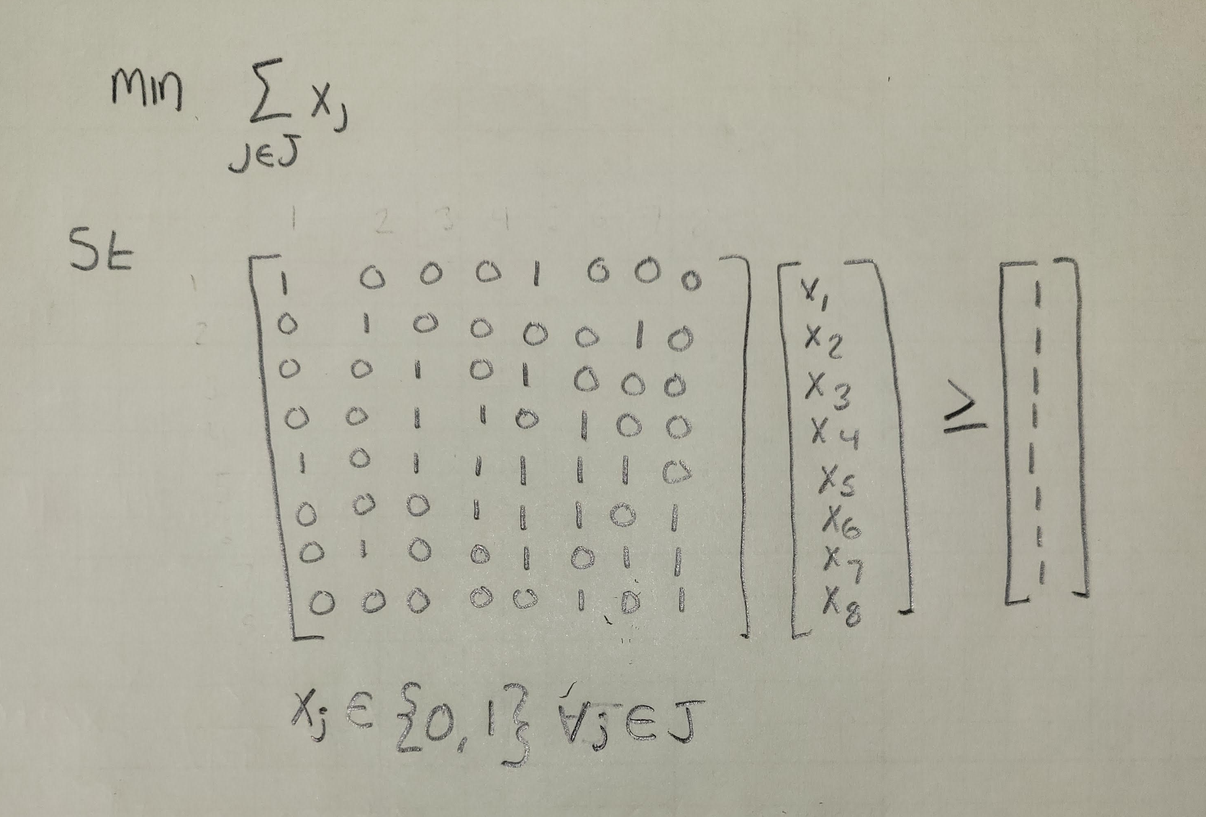

The constraint must be an inequality in this problem because we need to make sure we cover all locations and it is acceptable if one is covered more than once. If we set it to an equality we would be forcing each post to be covered exactly once which may not be possible and may make the problem infeasable.

In [69]:
I = 1:8
J = 1:8
N = Dict(1 => [1, 5],
         2 => [2, 7],
         3 => [3, 4, 5],
         4 => [3, 4, 6],
         5 => [1, 3, 5, 6, 7],
         6 => [4, 5, 6, 8],
         7 => [2, 5, 7, 8],
         8 => [6, 7, 8]);


### 3(b): Locate posts and verify coverage

Implement and solve your model, using `x[j]` for the binary decisions.
Report the minimum number of posts and their locations. For every district,
list the selected posts that protect it, verifying that none is unprotected.
Any optimal set of locations is acceptable. No column generation or routing
algorithm is required.


In [70]:
# Build and solve the minimum set-covering model.
# Report open locations and, for each district, the open posts
# protecting it.

a=Model(HiGHS.Optimizer)

@variable(a,x[J], Bin)


n = length(N)
N2 = zeros(Int, n, n)

for (row, cols) in N
    N2[row, cols] .= 1
end

b= [1
    1
    1
    1
    1
    1
    1
    1]

@constraint(a, N2*x .>=b)

@objective(a, Min, sum(x[j] for j in J))

optimize!(a)
if !is_solved_and_feasible(a; allow_local = false)
    error("No optimal primal solution: $(termination_status(a)), $(primal_status(a))")
end

println(termination_status(a))

println("number of posts needed: ",objective_value(a))
println("number of each post:")
for i in 1:length(x)
    println("post ", i, " status ",value.(x[i]))
end

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 8 rows; 8 cols; 26 nonzeros; 8 integer variables (8 binary)
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e+00, 1e+00]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 1e+00]
Presolving model
8 rows, 8 cols, 26 nonzeros 0s
0 rows, 0 cols, 0 nonzeros 0s
Presolve reductions: rows 0(-8); columns 0(-8); nonzeros 0(-26) - Reduced to empty
Presolve: Optimal

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate node; U => Unbounded; X => User solution; Y => HiGHS solution;
     Z => ZI Round; l => Trivial lower; p => Trivial point; u => Trivial upper; z => Trivial zero

        Nodes      |    B&B Tree     |            Ob

**Your results and interpretation:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

The minimum number of posts is 3, being post 3 which protects posts 3,4,and 5 post 5 which protects posts 1, 3, 5, 6, and 7 and post 7 which protects 2, 5, 7 and 8.

|Post| Protector |
|:--|--:|
|1|5|
|2|7|
|3|3,5|
|4|3|
|5|3,5,7|
|6|5|
|7|5,7|
|8|7|



## Collaboration and LLM-use statement — required

Complete this statement as the **very last part of your homework**. Be specific enough that a reader can understand what work you did yourself and how others or LLMs helped you learn.

- **People:** Give the name of every person you collaborated with, identify the problem/subpart you discussed, and explain the nature of the collaboration. If you worked alone, explicitly state that you did not collaborate with anyone.
- **LLMs/tools:** Name every LLM or AI assistant you used and identify the model/version as precisely as available. If the interface did not show a model/version, say so. If you used none, explicitly state that you did not use an LLM or AI assistant.
- **Specific assistance and learning:** For each tool, identify the problem/subpart, describe what you asked it to help with, what suggestions you used or rejected, and how the interaction helped you understand the mathematics or implementation. Explain how you checked the suggestions. “I used ChatGPT for help” is not sufficiently specific.

Disclosure does not replace the requirement that your submitted formulation, implementation, and explanation be your own work and that you understand them.


**People and collaboration:**

[Names, problem/subparts, and what you discussed; or explicitly state that you worked alone.]

I worked alone

**LLMs/tools and models:**

[Tool names and models/versions, or explicitly state that you used none.]

I utilized Gemini 3.6.

**How I used the assistance, what I learned, and how I checked it:**

[Specific details for each tool and relevant problem/subpart; state not applicable if you used none.]

I used it to help debug my code in problem 1a to help debug and explain the errors I was having that were ultimately caused by accidently having a extra bracket in my [j in T] (it was [j]in T]). 

I used in in problem 2b as well to help explain the difference between value() and value.(). I learned that value.() is needed for any values that are arrays and value. works on scalars


